# Gradient Flows of the Gaussian Sinkhorn divergence 

In [1]:
# Imports
import torch
torch.set_default_dtype(torch.float64)
from backend import * # See backend.py
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np

In [2]:
# Parameters
sigma_0 = torch.tensor([[.6, .3],
                        [.3, .6]])
sigma_target_non_singular = torch.diag(torch.tensor([1., .2]))
sigma_target_singular = torch.diag(torch.tensor([1., 0.]))
t = torch.linspace(0, 3, 200)
blur = .5
# Compute flows
sigma_t_non_singular = GaussianWGFS(blur, sigma_target_non_singular).integrate(sigma_0, t)
sigma_t_singular = GaussianWGFS(blur, sigma_target_singular).integrate(sigma_0, t)

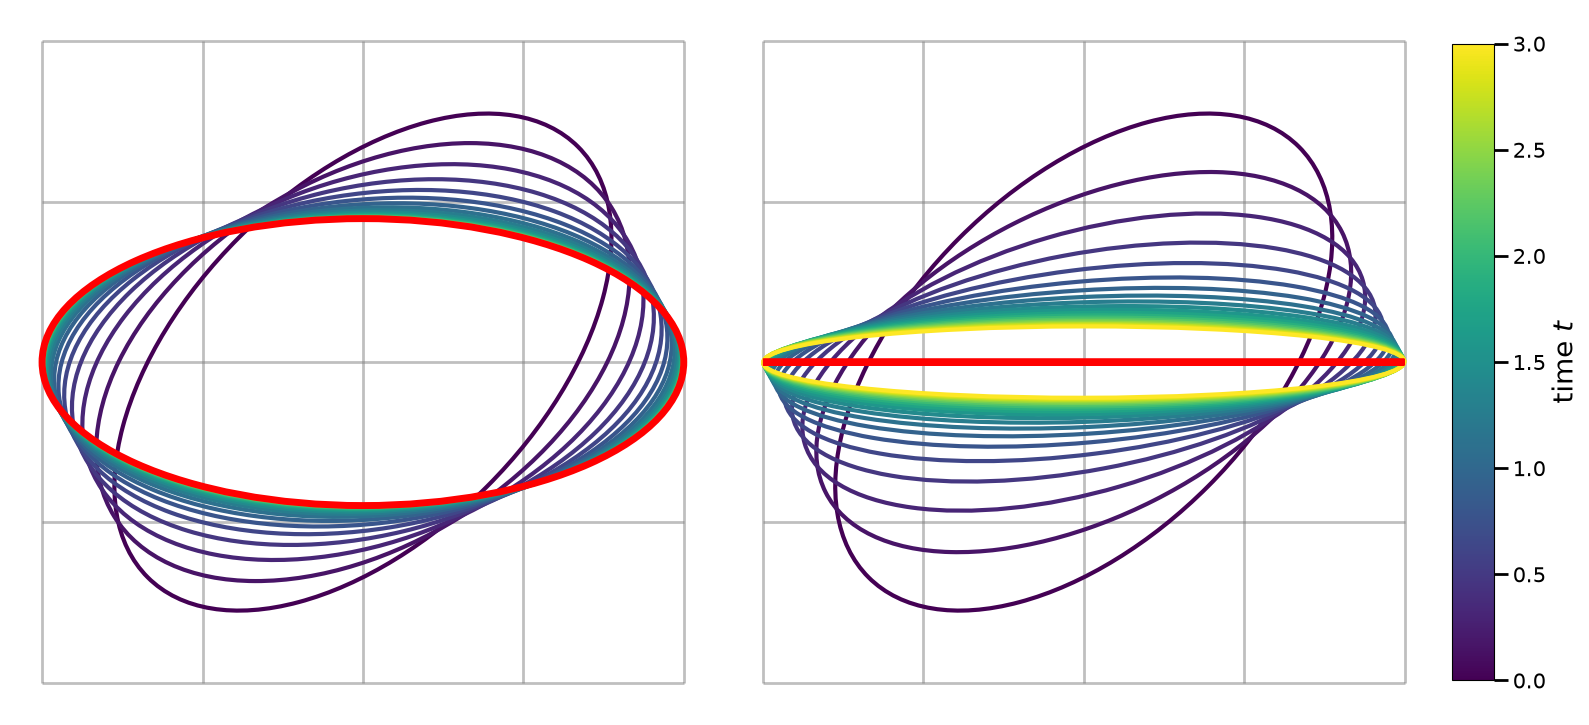

In [3]:
# Figure 1
figsize = (16, 8)
xm, xM = -1, 1
ym, yM = -1, 1

fig, (ax1, ax2, cax) = plt.subplots(1, 3, figsize=figsize, width_ratios=[1, 1, .06])
for ax, sig_t, sig_target in zip([ax1, ax2], [sigma_t_non_singular, sigma_t_singular], [sigma_target_non_singular, sigma_target_singular]):
    ax.set_xlim(xm-.1, xM+.1)
    ax.set_ylim(ym-.1, yM+.1)
    ax.hlines(np.arange(ym, yM+blur, blur), xm , xM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.vlines(np.arange(xm, xM+blur, blur), ym , yM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax = plot_gaussian_flow(ax, sig_t, sig_target, subsample=10, kw=dict(linewidth=3), kw_target=dict(linewidth=5))

fig.colorbar(mpl.cm.ScalarMappable(cmap=plt.get_cmap('viridis'), norm=mpl.colors.Normalize(vmin=0, vmax=t[-1])), cax=cax)
cax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
cax.set_ylabel("time $t$", size=20)
fig.tight_layout()
pos = cax.get_position()
cax.set_position([
    pos.x0,
    pos.y0 + 0.075 * pos.height,
    pos.width,
    0.85 * pos.height
])

In [4]:
# Parameters
sigma_0_ortho = torch.tensor([[0., 0.],
                              [0, 1.]])
t = torch.linspace(0, 2, 200)
sigma_target = torch.diag(torch.tensor([1., 0.]))

def rot(theta):
    return torch.tensor([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])
P = rot(0.01)
sigma_0_non_ortho = P @ torch.tensor([[0., 0.],
                                      [0, 1.]]) @ P.T

# Compute flows
sigma_t_ortho = GaussianWGFS(blur, sigma_target).integrate(sigma_0_ortho, t)
sigma_t_non_ortho = GaussianWGFS(blur, sigma_target).integrate(sigma_0_non_ortho, t)

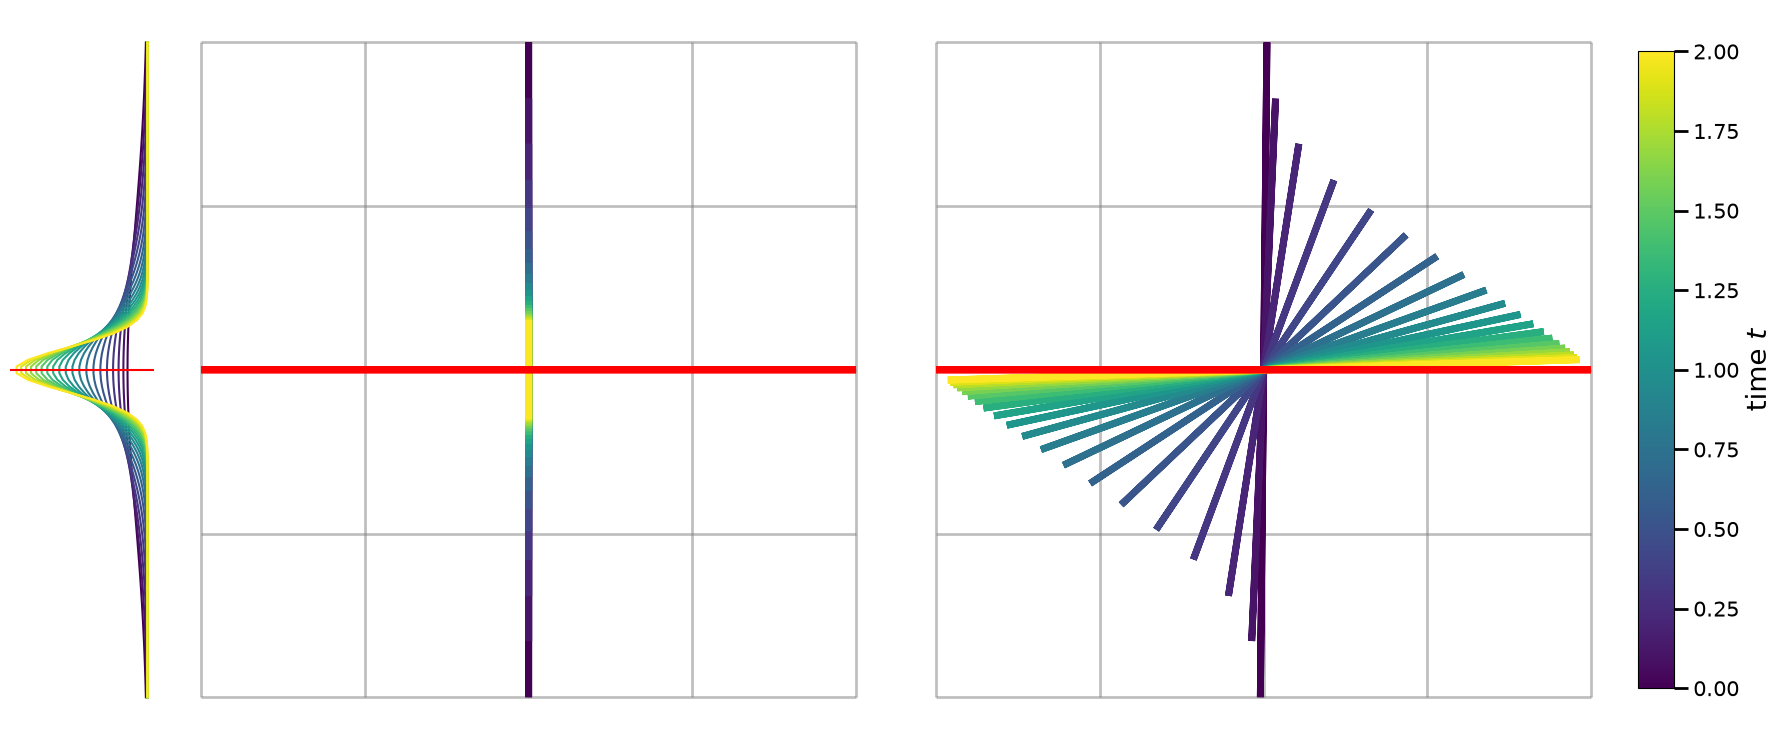

In [5]:
# Figure 2
figsize = (16, 8)
xm, xM = -1, 1
ym, yM = -1, 1

fig = plt.figure(figsize=(18, 8))
spec = fig.add_gridspec(1, 3, width_ratios=[1, 1, .05])
ax1 = fig.add_subplot(spec[0, 0])
ax1.set_aspect("equal")
ax1.set_xlim(xm-.1, xM+.1)
ax1.set_ylim(ym-.1, yM+.1)
ax1_y = ax1.inset_axes(
    [-.22, 0., .2, 1],
    transform=ax1.transAxes,
    sharey=ax1
)
ax2 = fig.add_subplot(spec[0, 1])
ax2.set_aspect("equal")
ax2.set_xlim(xm-.1, xM+.1)
ax2.set_ylim(ym-.1, yM+.1)
cax = fig.add_subplot(spec[0, 2])


for ax, sig_t, sig_target in zip([ax1, ax2], [sigma_t_ortho, sigma_t_non_ortho], [sigma_target]*2):
    
    ax.hlines(np.arange(ym, yM+blur, blur), xm , xM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.vlines(np.arange(xm, xM+blur, blur), ym , yM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.set_axis_off()
    ax = plot_gaussian_flow(ax, sig_t, sig_target, subsample=10, kw=dict(linewidth=5), kw_target=dict(linewidth=5))
s = .2

plot_gaussian_flow_1D(ax1_y,s*sigma_t_ortho[:, 1, 1], xm, xM, rotate=True, var_target=s*sigma_target[1, 1], subsample=10)
ax1_y.set_axis_off()
fig.colorbar(mpl.cm.ScalarMappable(cmap=plt.get_cmap('viridis'), norm=mpl.colors.Normalize(vmin=0, vmax=t[-1])), cax=cax)
cax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
cax.set_ylabel("time $t$", size=20)

fig.tight_layout()
fig.subplots_adjust(left=0.1)
pos = cax.get_position()
cax.set_position([
    pos.x0,
    pos.y0 + 0.075 * pos.height,
    pos.width,
    0.85 * pos.height
])

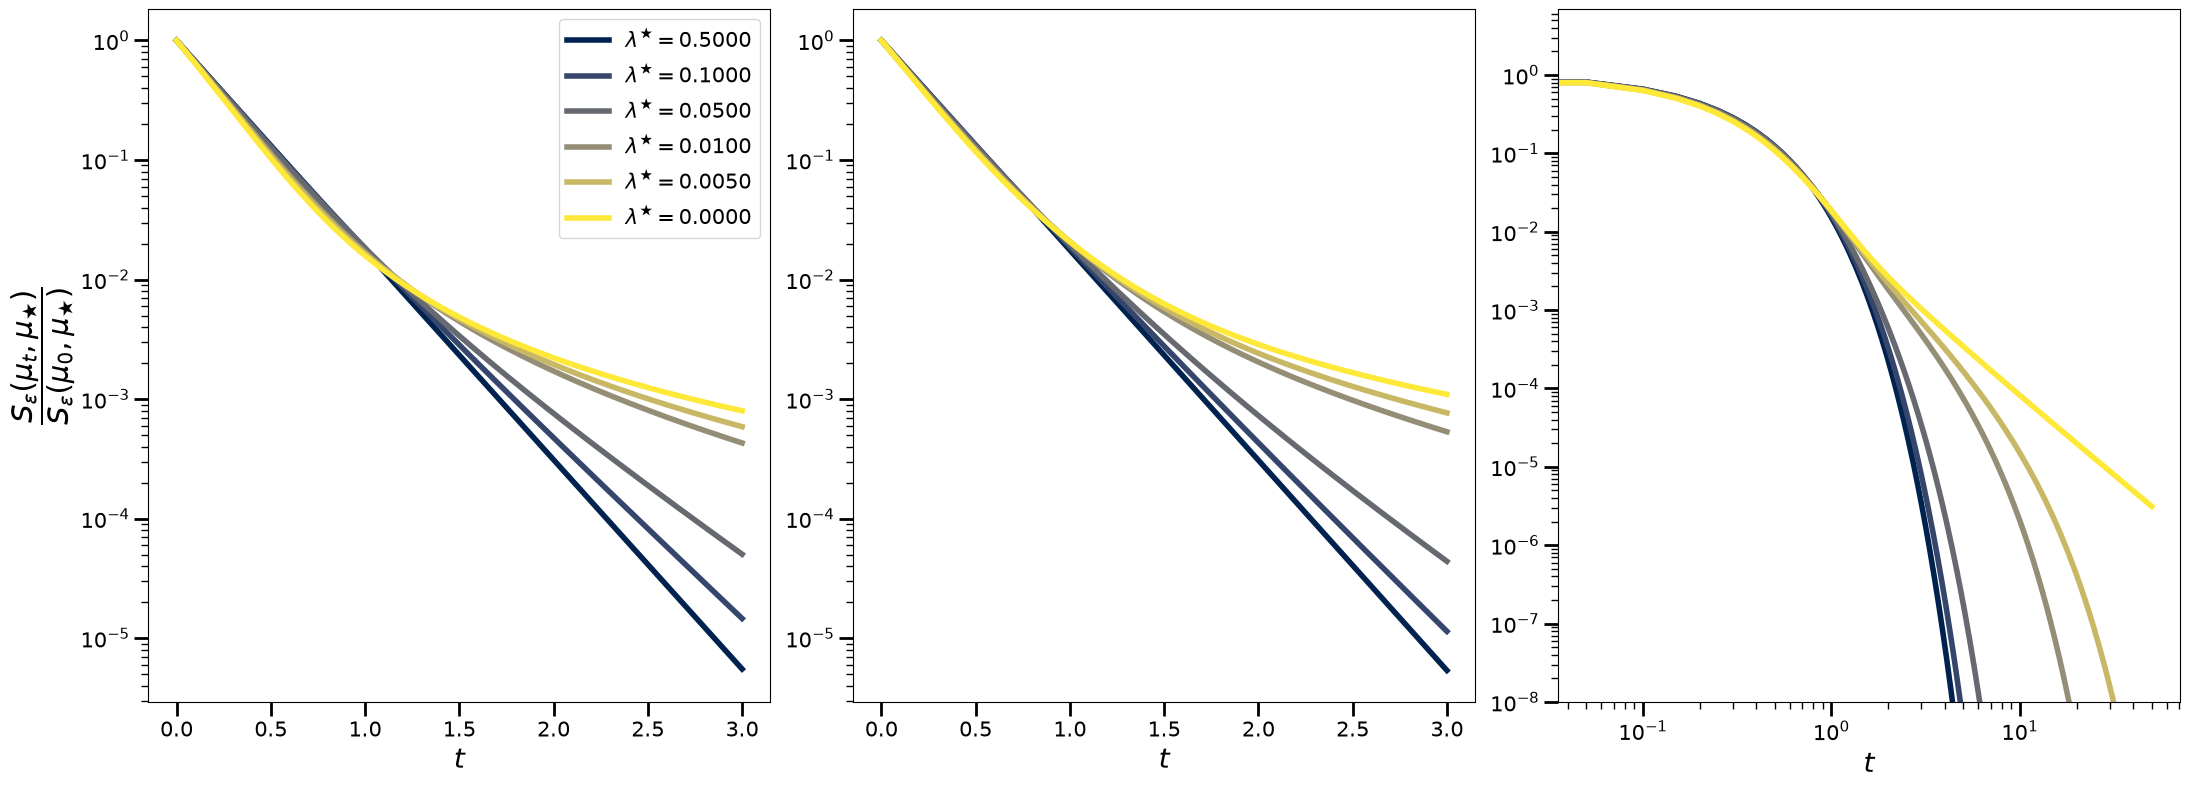

In [6]:
# Figure 3
fig = plt.figure(figsize=(22, 8))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2, sharey=ax1)
ax3 = fig.add_subplot(1, 3, 3)
lam_list = [5e-1, 1e-1, 5e-2, 1e-2, 5e-3, 0]
n = len(lam_list)
sigma_0_list = [torch.tensor([[1., 0],
                              [0., 1.]])]*n

sigma_star_list = [torch.tensor([[1., 0.],
                                 [0., l]]) for l in lam_list]
blur_list = [.5]*n
t = torch.linspace(0, 3, 200)
ax1 = plot_cv_speed(ax1, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\lambda^{\bigstar} = "+ f'{l:.4f}$' for l in lam_list],)

sigma_0_list = [torch.tensor([[.6, .3],
                              [.3, .6]])]*n
ax2 = plot_cv_speed(ax2, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\lambda^{\bigstar} = " + f'{l:.4f}$' for l in lam_list], showylabel=False, showlegend=False)
ax3 = plot_cv_speed(ax3, sigma_0_list, sigma_star_list, blur_list, torch.linspace(0, 50, 1000), labels=[r"$\lambda^{\bigstar} = " + f'{l:.4f}$' for l in lam_list], showylabel=False, showlegend=False)
ax3.set_ylim(bottom = 1e-8)
ax3.set_xscale('log')

fig.tight_layout()

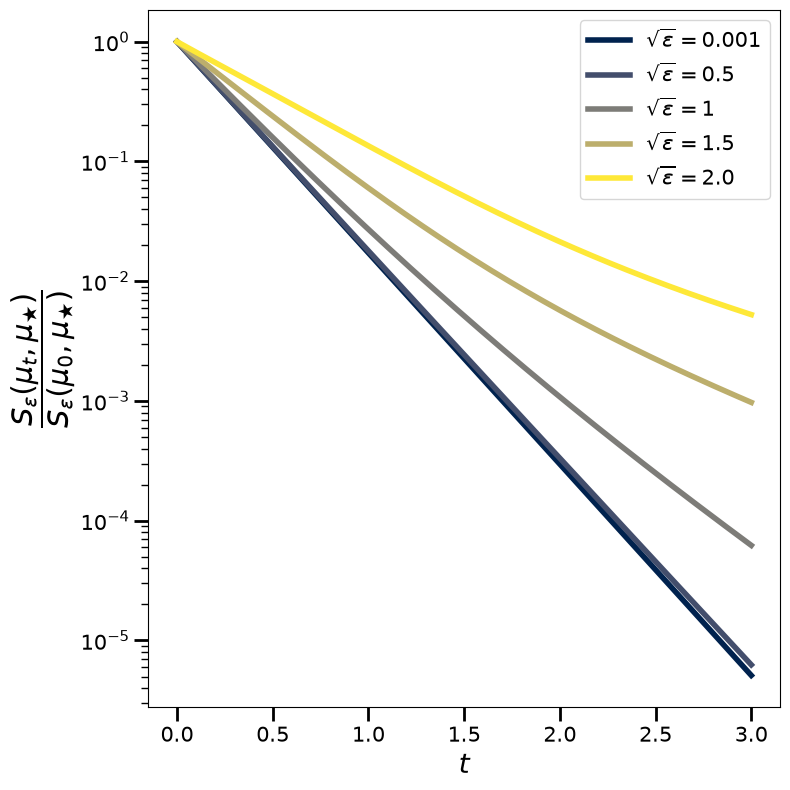

In [7]:
# Figure 4
blur_list = [.001, .5, 1, 1.5, 2.]
n = len(blur_list)
fig, ax1 = plt.subplots(figsize=(8, 8))
sigma_0_list = [torch.tensor([[.6, .3],
                          [.3, .6]])]*n
sigma_star_list = [torch.diag(torch.tensor([1., .2]))]*n
t = torch.linspace(0, 3, 200)
ax1 = plot_cv_speed(ax1, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\sqrt{\varepsilon} = "+f"{blur}$" for blur in blur_list])
fig.tight_layout()